In [6]:
import pandas as pd


In [7]:
players = pd.read_csv(
    "cleaned_data/player_appearances_cleaned_v4.csv",
    low_memory=False
)
players.shape

(108681, 24)

In [8]:
group_cols = ["season", "fixture", "team_name_corrected"]

group_sizes = players.groupby(group_cols).size()

print("Number of team-fixture groups:", len(group_sizes))
print("\nPlayers per team-fixture:")
print(group_sizes.describe())

Number of team-fixture groups: 7600

Players per team-fixture:
count    7600.000000
mean       14.300132
std         1.027609
min        11.000000
25%        14.000000
50%        14.000000
75%        15.000000
max        17.000000
dtype: float64


In [9]:
first_group = players.groupby(group_cols).get_group(
    tuple(players[group_cols].iloc[0])
)

first_group[
    ["season", "fixture", "team_name_corrected",
     "element", "name", "position", "minutes", "result"]
]

,season,fixture,team_name_corrected,element,name,position,minutes,result
0,2016-17,3,Everton,142,Aaron_Lennon,Midfielder,15,D
31,2016-17,3,Everton,144,Arouna_Koné,Forward,23,D
97,2016-17,3,Everton,137,Gareth_Barry,Midfielder,84,D
105,2016-17,3,Everton,141,Gerard_Deulofeu,Midfielder,67,D
118,2016-17,3,Everton,488,Idrissa_Gueye,Midfielder,90,D
124,2016-17,3,Everton,136,James_McCarthy,Midfielder,90,D
154,2016-17,3,Everton,133,Kevin_Mirallas,Midfielder,75,D
159,2016-17,3,Everton,125,Leighton_Baines,Defender,90,D
170,2016-17,3,Everton,124,Maarten_Stekelenburg,Goalkeeper,90,D
178,2016-17,3,Everton,495,Mason_Holgate,Defender,90,D


Create player pairs for testing-- tuples

In [10]:
from itertools import combinations

player_ids = first_group["element"].tolist()

pairs = list(combinations(player_ids, 2))

print("Number of players:", len(player_ids))
print("Number of pairs:", len(pairs))
print("\nFirst 10 pairs:")
print(pairs[:10])

Number of players: 14
Number of pairs: 91

First 10 pairs:
[(142, 144), (142, 137), (142, 141), (142, 488), (142, 136), (142, 133), (142, 125), (142, 124), (142, 495), (142, 127)]


Create dataframe 

In [11]:
pairs_df = pd.DataFrame(
    pairs,
    columns=["player_1", "player_2"]
)

pairs_df.head(10)

,player_1,player_2
0,142,144
1,142,137
2,142,141
3,142,488
4,142,136
5,142,133
6,142,125
7,142,124
8,142,495
9,142,127


In [12]:
pairs_df["season"] = first_group["season"].iloc[0]
pairs_df["fixture"] = first_group["fixture"].iloc[0]
pairs_df["team"] = first_group["team_name_corrected"].iloc[0]
pairs_df["result"] = first_group["result"].iloc[0]

pairs_df.head(10)

,player_1,player_2,season,fixture,team,result
0,142,144,2016-17,3,Everton,D
1,142,137,2016-17,3,Everton,D
2,142,141,2016-17,3,Everton,D
3,142,488,2016-17,3,Everton,D
4,142,136,2016-17,3,Everton,D
5,142,133,2016-17,3,Everton,D
6,142,125,2016-17,3,Everton,D
7,142,124,2016-17,3,Everton,D
8,142,495,2016-17,3,Everton,D
9,142,127,2016-17,3,Everton,D


Put tuples in ascending order to standarize values of alternating elements-- always (lower, higher) tuple

In [13]:
pairs_df[["player_1", "player_2"]] = pd.DataFrame(
    [sorted(pair) for pair in pairs_df[["player_1", "player_2"]].itertuples(index=False, name=None)],
    index=pairs_df.index
)

pairs_df.head(10)

,player_1,player_2,season,fixture,team,result
0,142,144,2016-17,3,Everton,D
1,137,142,2016-17,3,Everton,D
2,141,142,2016-17,3,Everton,D
3,142,488,2016-17,3,Everton,D
4,136,142,2016-17,3,Everton,D
5,133,142,2016-17,3,Everton,D
6,125,142,2016-17,3,Everton,D
7,124,142,2016-17,3,Everton,D
8,142,495,2016-17,3,Everton,D
9,127,142,2016-17,3,Everton,D


In [14]:
print("Total pairs:", len(pairs_df))

print("Duplicate pairs:",
      pairs_df.duplicated(
          subset=["player_1", "player_2"]
      ).sum())

print("Incorrectly ordered pairs:",
      (pairs_df["player_1"] >= pairs_df["player_2"]).sum())

Total pairs: 91
Duplicate pairs: 0
Incorrectly ordered pairs: 0


In [15]:
for group_key, group in players.groupby(group_cols):

    print("Group:", group_key)
    print("Number of players:", len(group))
    print("Result:", group["result"].iloc[0])
    print()

    break

Group: ('2016-17', 1, 'Burnley')
Number of players: 13
Result: L



Generate Pairs Inside the Loop

In [16]:
for group_key, group in players.groupby(group_cols):

    player_ids = sorted(group["element"].tolist())

    group_pairs = list(combinations(player_ids, 2))

    print("Group:", group_key)
    print("Players:", len(player_ids))
    print("Pairs generated:", len(group_pairs))
    print("First 10 pairs:", group_pairs[:10])

    break

Group: ('2016-17', 1, 'Burnley')
Players: 13
Pairs generated: 78
First 10 pairs: [(54, 55), (54, 56), (54, 57), (54, 58), (54, 61), (54, 62), (54, 63), (54, 64), (54, 67), (54, 68)]


Collect pairs from all 7600 groups-- nested loops

In [18]:
all_pairs = []

for group_key, group in players.groupby(group_cols):

    season, fixture, team = group_key
    result = group["result"].iloc[0]

    player_ids = sorted(group["element"].tolist())

    for player_1, player_2 in combinations(player_ids, 2):
        all_pairs.append(
            (season, fixture, team, player_1, player_2, result)
        )

    #if len(all_pairs) >= 250:
    #    break

print("Pairs collected:", len(all_pairs))
print("First 5 records:")
print(all_pairs[:5])

Pairs collected: 726748
First 5 records:
[('2016-17', 1, 'Burnley', 54, 55, 'L'), ('2016-17', 1, 'Burnley', 54, 56, 'L'), ('2016-17', 1, 'Burnley', 54, 57, 'L'), ('2016-17', 1, 'Burnley', 54, 58, 'L'), ('2016-17', 1, 'Burnley', 54, 61, 'L')]


Convert complete list into dataframe

In [19]:
all_pairs_df = pd.DataFrame(
    all_pairs,
    columns=[
        "season",
        "fixture",
        "team",
        "player_1",
        "player_2",
        "result"
    ]
)

print("Dataset shape:", all_pairs_df.shape)

all_pairs_df.head(10)

Dataset shape: (726748, 6)


,season,fixture,team,player_1,player_2,result
0,2016-17,1,Burnley,54,55,L
1,2016-17,1,Burnley,54,56,L
2,2016-17,1,Burnley,54,57,L
3,2016-17,1,Burnley,54,58,L
4,2016-17,1,Burnley,54,61,L
5,2016-17,1,Burnley,54,62,L
6,2016-17,1,Burnley,54,63,L
7,2016-17,1,Burnley,54,64,L
8,2016-17,1,Burnley,54,67,L
9,2016-17,1,Burnley,54,68,L


Check math

In [20]:
expected_pairs = (
    group_sizes * (group_sizes - 1) // 2
).sum()

actual_pairs = len(all_pairs_df)

print("Expected pairs:", expected_pairs)
print("Actual pairs:", actual_pairs)
print("Difference:", actual_pairs - expected_pairs)

Expected pairs: 726748
Actual pairs: 726748
Difference: 0


Check for duplicates and ordering errors

In [21]:
duplicate_pairs = all_pairs_df.duplicated(
    subset=[
        "season",
        "fixture",
        "team",
        "player_1",
        "player_2"
    ]
).sum()

incorrect_order = (
    all_pairs_df["player_1"] >= all_pairs_df["player_2"]
).sum()

missing_values = all_pairs_df.isnull().sum()

print("Duplicate pair appearances:", duplicate_pairs)
print("Incorrectly ordered pairs:", incorrect_order)
print("\nMissing values:")
print(missing_values)

Duplicate pair appearances: 0
Incorrectly ordered pairs: 0

Missing values:
season      0
fixture     0
team        0
player_1    0
player_2    0
result      0
dtype: int64


Save player pair dataset in csv and excel

In [22]:
all_pairs_df.to_csv(
    "cleaned_data/player_pairs_v1.csv",
    index=False
)

print("Player-pair dataset saved.")

Player-pair dataset saved.


In [23]:
all_pairs_df.to_excel(
    "cleaned_data/player_pairs_v1.xlsx",
    index=False,
    sheet_name="Player Pairs"
)

print("Excel file saved successfully.")

Excel file saved successfully.


Aggregate player pairs, matches, wins, draws, loses

In [24]:
pair_group_cols = [
    "season",
    "team",
    "player_1",
    "player_2"
]

In [25]:
pair_stats = (
    all_pairs_df.groupby(pair_group_cols)
    .agg(
        matches_together=("result", "size"),
        wins=("result", lambda x: (x == "W").sum()),
        draws=("result", lambda x: (x == "D").sum()),
        losses=("result", lambda x: (x == "L").sum())
    )
    .reset_index()
)

print("Unique pair-season-team combinations:", len(pair_stats))

pair_stats.head(10)

Unique pair-season-team combinations: 63320


,season,team,player_1,player_2,matches_together,wins,draws,losses
0,2016-17,Arsenal,1,2,1,0,0,1
1,2016-17,Arsenal,1,3,2,0,1,1
2,2016-17,Arsenal,1,5,1,0,1,0
3,2016-17,Arsenal,1,6,2,0,1,1
4,2016-17,Arsenal,1,10,2,0,1,1
5,2016-17,Arsenal,1,12,2,0,1,1
6,2016-17,Arsenal,1,13,2,0,1,1
7,2016-17,Arsenal,1,14,1,0,1,0
8,2016-17,Arsenal,1,16,1,0,0,1
9,2016-17,Arsenal,1,18,1,0,0,1


Validate Aggregation-- total=wins+loses+draws 

In [26]:
result_total = (
    pair_stats["wins"] +
    pair_stats["draws"] +
    pair_stats["losses"]
)

invalid_rows = (
    result_total != pair_stats["matches_together"]
).sum()

total_appearances = pair_stats["matches_together"].sum()

print("Invalid pair records:", invalid_rows)
print("Original pair appearances:", len(all_pairs_df))
print("Aggregated pair appearances:", total_appearances)
print("Difference:", total_appearances - len(all_pairs_df))

Invalid pair records: 0
Original pair appearances: 726748
Aggregated pair appearances: 726748
Difference: 0


Calculate pair performance-- points per game, win rate/ add columns

In [27]:
pair_stats["win_pct"] = (
    pair_stats["wins"] /
    pair_stats["matches_together"] * 100
).round(2)

pair_stats["points_per_match"] = (
    (pair_stats["wins"] * 3 + pair_stats["draws"]) /
    pair_stats["matches_together"]
).round(2)

pair_stats.head(10)

,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match
0,2016-17,Arsenal,1,2,1,0,0,1,0.0,0.0
1,2016-17,Arsenal,1,3,2,0,1,1,0.0,0.5
2,2016-17,Arsenal,1,5,1,0,1,0,0.0,1.0
3,2016-17,Arsenal,1,6,2,0,1,1,0.0,0.5
4,2016-17,Arsenal,1,10,2,0,1,1,0.0,0.5
5,2016-17,Arsenal,1,12,2,0,1,1,0.0,0.5
6,2016-17,Arsenal,1,13,2,0,1,1,0.0,0.5
7,2016-17,Arsenal,1,14,1,0,1,0,0.0,1.0
8,2016-17,Arsenal,1,16,1,0,0,1,0.0,0.0
9,2016-17,Arsenal,1,18,1,0,0,1,0.0,0.0


Min pair appearance together of 10

In [28]:
qualified_pairs = pair_stats[
    pair_stats["matches_together"] >= 10
].copy()

print("Total combinations:", len(pair_stats))
print("Qualified combinations:", len(qualified_pairs))

print(
    "Percentage retained:",
    round(len(qualified_pairs) / len(pair_stats) * 100, 2)
)

qualified_pairs.head(10)

Total combinations: 63320
Qualified combinations: 30880
Percentage retained: 48.77


,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match
16,2016-17,Arsenal,2,3,32,20,5,7,62.50,2.03
18,2016-17,Arsenal,2,5,16,10,1,5,62.50,1.94
19,2016-17,Arsenal,2,6,30,19,4,7,63.33,2.03
20,2016-17,Arsenal,2,7,11,10,0,1,90.91,2.73
23,2016-17,Arsenal,2,10,33,20,5,8,60.61,1.97
25,2016-17,Arsenal,2,12,35,22,5,8,62.86,2.03
26,2016-17,Arsenal,2,13,25,13,4,8,52.00,1.72
27,2016-17,Arsenal,2,14,30,21,4,5,70.00,2.23
29,2016-17,Arsenal,2,16,21,14,3,4,66.67,2.14
31,2016-17,Arsenal,2,18,27,14,5,8,51.85,1.74


Sort player combinations

In [29]:
top_pairs = qualified_pairs.sort_values(
    by=["win_pct", "matches_together"],
    ascending=[False, False]
)

top_pairs.head(20)

,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match
20284,2019-20,Liverpool,181,200,20,20,0,0,100.0,3.0
20441,2019-20,Liverpool,191,200,19,19,0,0,100.0,3.0
15527,2018-19,Man City,264,271,15,15,0,0,100.0,3.0
15484,2018-19,Man City,260,279,14,14,0,0,100.0,3.0
15607,2018-19,Man City,270,279,13,13,0,0,100.0,3.0
15616,2018-19,Man City,271,279,13,13,0,0,100.0,3.0
15646,2018-19,Man City,276,279,13,13,0,0,100.0,3.0
32639,2021-22,Liverpool,221,225,13,13,0,0,100.0,3.0
47058,2023-24,Man City,365,566,13,13,0,0,100.0,3.0
15528,2018-19,Man City,264,272,12,12,0,0,100.0,3.0


Calculate team performance baseline

In [30]:
team_matches = players[
    ["season", "fixture", "team_name_corrected", "result"]
].drop_duplicates()

print("Total team-match records:", len(team_matches))

team_matches.head(10)

Total team-match records: 7600


,season,fixture,team_name_corrected,result
0,2016-17,3,Everton,D
1,2016-17,8,Arsenal,L
2,2016-17,4,Hull,W
4,2016-17,6,Middlesbrough,D
6,2016-17,8,Liverpool,W
7,2016-17,9,Bournemouth,L
8,2016-17,7,Watford,D
9,2016-17,5,Sunderland,L
10,2016-17,10,West Ham,L
12,2016-17,4,Leicester,L


Calculate team season baselines

In [31]:
team_baselines = (
    team_matches.groupby(["season", "team_name_corrected"])
    .agg(
        matches=("result", "size"),
        wins=("result", lambda x: (x == "W").sum()),
        draws=("result", lambda x: (x == "D").sum()),
        losses=("result", lambda x: (x == "L").sum())
    )
    .reset_index()
)

print("Team-season records:", len(team_baselines))

team_baselines.head(10)

Team-season records: 200


,season,team_name_corrected,matches,wins,draws,losses
0,2016-17,Arsenal,38,23,6,9
1,2016-17,Bournemouth,38,12,10,16
2,2016-17,Burnley,38,11,7,20
3,2016-17,Chelsea,38,30,3,5
4,2016-17,Crystal Palace,38,12,5,21
5,2016-17,Everton,38,17,10,11
6,2016-17,Hull,38,9,7,22
7,2016-17,Leicester,38,12,8,18
8,2016-17,Liverpool,38,22,10,6
9,2016-17,Man City,38,23,9,6


Calc team baseline performance-- season

In [32]:
team_baselines["team_win_pct"] = (
    team_baselines["wins"] /
    team_baselines["matches"] * 100
).round(2)

team_baselines["team_points_per_match"] = (
    (team_baselines["wins"] * 3 + team_baselines["draws"]) /
    team_baselines["matches"]
).round(2)

team_baselines.head(10)

,season,team_name_corrected,matches,wins,draws,losses,team_win_pct,team_points_per_match
0,2016-17,Arsenal,38,23,6,9,60.53,1.97
1,2016-17,Bournemouth,38,12,10,16,31.58,1.21
2,2016-17,Burnley,38,11,7,20,28.95,1.05
3,2016-17,Chelsea,38,30,3,5,78.95,2.45
4,2016-17,Crystal Palace,38,12,5,21,31.58,1.08
5,2016-17,Everton,38,17,10,11,44.74,1.61
6,2016-17,Hull,38,9,7,22,23.68,0.89
7,2016-17,Leicester,38,12,8,18,31.58,1.16
8,2016-17,Liverpool,38,22,10,6,57.89,2.00
9,2016-17,Man City,38,23,9,6,60.53,2.05


Merge team baselines with player contributions

In [33]:
pair_comparison = qualified_pairs.merge(
    team_baselines[
        ["season", "team_name_corrected",
         "team_win_pct", "team_points_per_match"]
    ],
    left_on=["season", "team"],
    right_on=["season", "team_name_corrected"],
    how="left",
    validate="many_to_one"
)

pair_comparison = pair_comparison.drop(
    columns=["team_name_corrected"]
)

print("Records after merge:", len(pair_comparison))

pair_comparison.head(10)

Records after merge: 30880


,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match,team_win_pct,team_points_per_match
0,2016-17,Arsenal,2,3,32,20,5,7,62.50,2.03,60.53,1.97
1,2016-17,Arsenal,2,5,16,10,1,5,62.50,1.94,60.53,1.97
2,2016-17,Arsenal,2,6,30,19,4,7,63.33,2.03,60.53,1.97
3,2016-17,Arsenal,2,7,11,10,0,1,90.91,2.73,60.53,1.97
4,2016-17,Arsenal,2,10,33,20,5,8,60.61,1.97,60.53,1.97
5,2016-17,Arsenal,2,12,35,22,5,8,62.86,2.03,60.53,1.97
6,2016-17,Arsenal,2,13,25,13,4,8,52.00,1.72,60.53,1.97
7,2016-17,Arsenal,2,14,30,21,4,5,70.00,2.23,60.53,1.97
8,2016-17,Arsenal,2,16,21,14,3,4,66.67,2.14,60.53,1.97
9,2016-17,Arsenal,2,18,27,14,5,8,51.85,1.74,60.53,1.97


In [34]:
print("Missing team win percentages:",
      pair_comparison["team_win_pct"].isnull().sum())

print("Missing team points per match:",
      pair_comparison["team_points_per_match"].isnull().sum())

Missing team win percentages: 0
Missing team points per match: 0


In [35]:
pair_comparison["win_pct_difference"] = (
    pair_comparison["win_pct"] -
    pair_comparison["team_win_pct"]
).round(2)

pair_comparison["points_difference"] = (
    pair_comparison["points_per_match"] -
    pair_comparison["team_points_per_match"]
).round(2)

pair_comparison.head(10)

,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match,team_win_pct,team_points_per_match,win_pct_difference,points_difference
0,2016-17,Arsenal,2,3,32,20,5,7,62.50,2.03,60.53,1.97,1.97,0.06
1,2016-17,Arsenal,2,5,16,10,1,5,62.50,1.94,60.53,1.97,1.97,-0.03
2,2016-17,Arsenal,2,6,30,19,4,7,63.33,2.03,60.53,1.97,2.80,0.06
3,2016-17,Arsenal,2,7,11,10,0,1,90.91,2.73,60.53,1.97,30.38,0.76
4,2016-17,Arsenal,2,10,33,20,5,8,60.61,1.97,60.53,1.97,0.08,0.00
5,2016-17,Arsenal,2,12,35,22,5,8,62.86,2.03,60.53,1.97,2.33,0.06
6,2016-17,Arsenal,2,13,25,13,4,8,52.00,1.72,60.53,1.97,-8.53,-0.25
7,2016-17,Arsenal,2,14,30,21,4,5,70.00,2.23,60.53,1.97,9.47,0.26
8,2016-17,Arsenal,2,16,21,14,3,4,66.67,2.14,60.53,1.97,6.14,0.17
9,2016-17,Arsenal,2,18,27,14,5,8,51.85,1.74,60.53,1.97,-8.68,-0.23


Identify strongest combinations

In [36]:
top_performing_pairs = pair_comparison.sort_values(
    by=["points_difference", "matches_together"],
    ascending=[False, False]
)

top_performing_pairs[
    [
        "season",
        "team",
        "player_1",
        "player_2",
        "matches_together",
        "points_per_match",
        "team_points_per_match",
        "points_difference"
    ]
].head(20)

,season,team,player_1,player_2,matches_together,points_per_match,team_points_per_match,points_difference
27115,2024-25,West Ham,517,591,12,2.33,1.13,1.20
20893,2023-24,Aston Villa,55,584,10,2.80,1.79,1.01
24661,2024-25,Brighton,113,147,10,2.60,1.61,0.99
16226,2021-22,Newcastle,291,697,11,2.27,1.29,0.98
11511,2020-21,Arsenal,17,23,12,2.58,1.61,0.97
11537,2020-21,Arsenal,23,526,12,2.58,1.61,0.97
14755,2021-22,Brighton,61,462,10,2.30,1.34,0.96
27114,2024-25,West Ham,517,588,12,2.08,1.13,0.95
16204,2021-22,Newcastle,109,291,13,2.23,1.29,0.94
3533,2017-18,Crystal Palace,117,221,11,2.09,1.16,0.93


Check against a 20 min games together

In [37]:
qualified_20 = pair_comparison[
    pair_comparison["matches_together"] >= 20
].copy()

top_20_pairs = qualified_20.sort_values(
    by=["points_difference", "matches_together"],
    ascending=[False, False]
)

print("Pairs with 10+ matches:", len(pair_comparison))
print("Pairs with 20+ matches:", len(qualified_20))

top_20_pairs[
    [
        "season",
        "team",
        "player_1",
        "player_2",
        "matches_together",
        "points_difference"
    ]
].head(20)

Pairs with 10+ matches: 30880
Pairs with 20+ matches: 13504


,season,team,player_1,player_2,matches_together,points_difference
10074,2019-20,Man City,215,220,21,0.63
10102,2019-20,Man City,220,443,20,0.62
7696,2018-19,Newcastle,317,482,23,0.56
19235,2022-23,Man City,305,312,21,0.56
26574,2024-25,Nott'm Forest,431,653,23,0.55
12347,2020-21,Everton,162,166,21,0.55
17707,2022-23,Brentford,81,90,20,0.55
17779,2022-23,Brentford,89,90,20,0.55
17792,2022-23,Brentford,90,95,20,0.55
3526,2017-18,Crystal Palace,117,126,23,0.54


In [39]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----------------------------------- ---- 8.4/9.5 MB 50.0 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 42.6 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 59.0 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 140.2 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
 


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Create Visualization

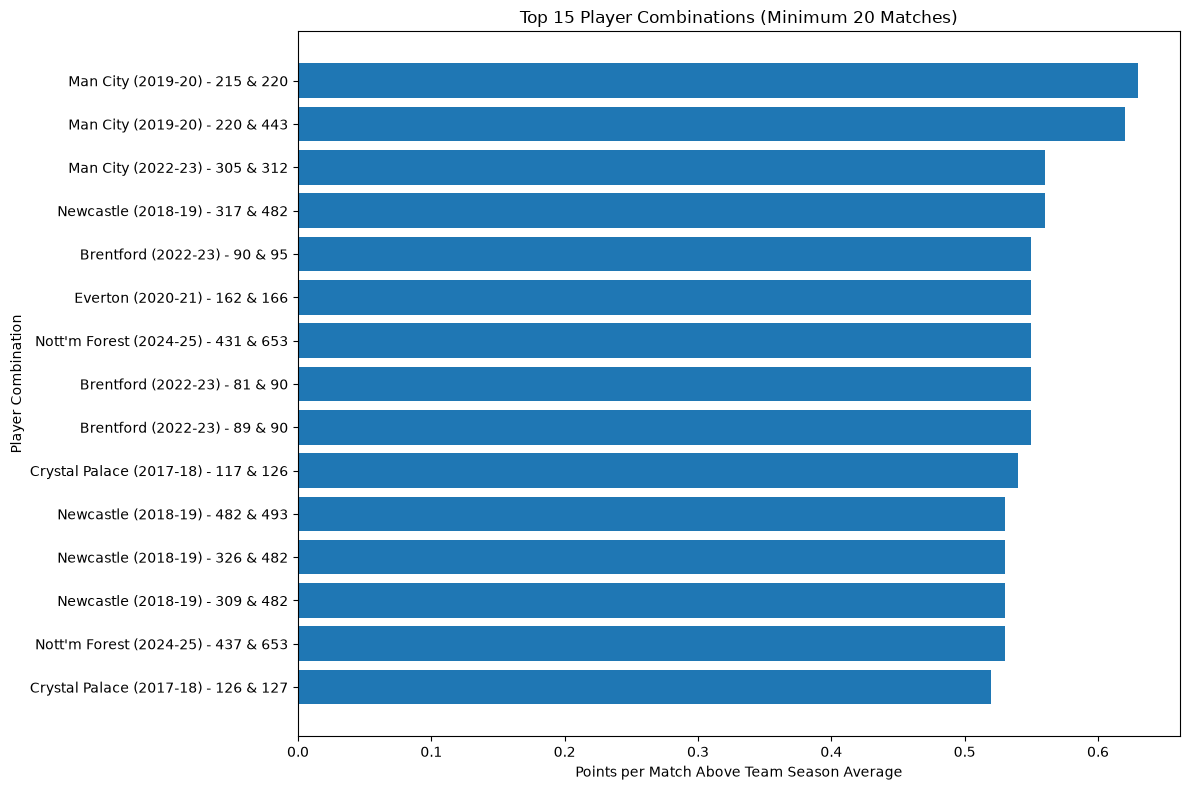

In [40]:
import matplotlib.pyplot as plt

plot_data = top_20_pairs.head(15).copy()

plot_data["pair_label"] = (
    plot_data["team"] + " (" +
    plot_data["season"] + ") - " +
    plot_data["player_1"].astype(str) + " & " +
    plot_data["player_2"].astype(str)
)

plot_data = plot_data.sort_values("points_difference")

plt.figure(figsize=(12, 8))

plt.barh(
    plot_data["pair_label"],
    plot_data["points_difference"]
)

plt.xlabel("Points per Match Above Team Season Average")
plt.ylabel("Player Combination")
plt.title("Top 15 Player Combinations (Minimum 20 Matches)")

plt.tight_layout()
plt.show()

In [41]:
from pathlib import Path

Path("cleaned_data").mkdir(exist_ok=True)

pair_stats.to_csv(
    "cleaned_data/player_pair_statistics_v1.csv",
    index=False
)

pair_stats.to_excel(
    "cleaned_data/player_pair_statistics_v1.xlsx",
    index=False
)

pair_comparison.to_csv(
    "cleaned_data/player_pair_comparison_v1.csv",
    index=False
)

pair_comparison.to_excel(
    "cleaned_data/player_pair_comparison_v1.xlsx",
    index=False
)

team_baselines.to_csv(
    "cleaned_data/team_season_baselines_v1.csv",
    index=False
)

team_baselines.to_excel(
    "cleaned_data/team_season_baselines_v1.xlsx",
    index=False
)

print("Player pair analysis datasets saved successfully.")

Player pair analysis datasets saved successfully.


In [42]:
top_performing_pairs.to_csv(
    "cleaned_data/top_performing_pairs_v1.csv",
    index=False
)

top_performing_pairs.to_excel(
    "cleaned_data/top_performing_pairs_v1.xlsx",
    index=False
)

print("Top-performing player combinations saved successfully.")
print("Records exported:", len(top_performing_pairs))

Top-performing player combinations saved successfully.
Records exported: 30880
